# 04 — Control 1: inverse initialization

### How to read this notebook
Run cells top to bottom. Each Markdown cell states the question and expected result **before** the code. The printed and plotted numbers are measurements, not claims made in advance. The shared functions live in `src/experiment.py`. Open Jupyter from the project root so imports work.

## Why this control?

Ordinary scaling changes the initial network function. To eliminate that explanation, start from a reference model and divide **only** the first-layer complex weight columns by $\alpha$:

$$W_c^{(\alpha)}=W_c^{(1)}/\alpha.$$

Then $\alpha X_c(W_c^{(\alpha)})^\top=X_c(W_c^{(1)})^\top$. Thus initial first-layer preactivations, ReLU gates, logits, and losses must match. We **do not** compensate SGD here, so effective complex updates can differ.

In [1]:
from src.experiment import *
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
print('PyTorch:', torch.__version__)

PyTorch: 2.14.1+cpu


In [2]:
alpha=5.0
x1,y=make_data(1024,seed=11,alpha=1)
xa,_=make_data(1024,seed=11,alpha=alpha)
ref=make_model(42)
scaled=make_model(42)
inverse_initialize(scaled,ref,alpha)
with torch.no_grad():
    print('Max initial logit difference:',(ref(x1)-scaled(xa)).abs().max().item())
    print('Max first-layer preactivation difference:',(ref.fc1(x1)-scaled.fc1(xa)).abs().max().item())
    assert torch.allclose(ref(x1),scaled(xa),atol=1e-5)

Max initial logit difference: 0.0
Max first-layer preactivation difference: 2.384185791015625e-07


## Compare matched-state gradients

Because the initial function matches, the upstream preactivation gradients match. The complex weight gradient in the scaled model should be $\alpha$ times the reference complex gradient, up to floating-point error.

In [3]:
criterion=torch.nn.BCEWithLogitsLoss()
ref.zero_grad(set_to_none=True)
scaled.zero_grad(set_to_none=True)
criterion(ref(x1),y).backward()
criterion(scaled(xa),y).backward()
g1=ref.fc1.weight.grad[:,1:3]
ga=scaled.fc1.weight.grad[:,1:3]
print('Max gradient mismatch:',(ga-alpha*g1).abs().max().item())
assert torch.allclose(ga,alpha*g1,atol=1e-5)

Max gradient mismatch: 4.470348358154297e-08


## Train without compensating SGD

The starting functions are identical. Now any divergence comes from training under different parameterizations, not from different initial logits or gates. The reference and scaled models use the same global SGD learning rate.

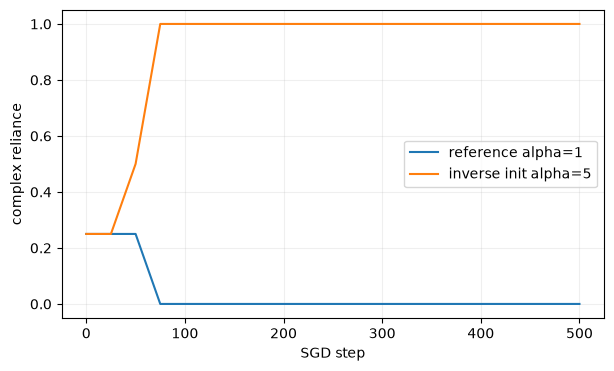

Final: {'step': 500, 'loss': 0.020811930298805237, 'accuracy': 1.0, 'complex_reliance': 0.0, 'simple_flip_rate': 1.0, 'complex_flip_rate': 0.0, 'simple_probability_change': 0.8917499780654907, 'complex_probability_change': 0.07035654038190842} {'step': 500, 'loss': 0.00524813961237669, 'accuracy': 1.0, 'complex_reliance': 1.0, 'simple_flip_rate': 0.0, 'complex_flip_rate': 1.0, 'simple_probability_change': 0.10001423209905624, 'complex_probability_change': 0.8910232186317444}


In [4]:
h1=train(ref,x1,y,steps=500,lr=0.03,alpha=1)
ha=train(scaled,xa,y,steps=500,lr=0.03,alpha=alpha)
plot_histories({'reference alpha=1':h1,'inverse init alpha=5':ha})
print('Final:',h1[-1],ha[-1])
save_rows([{'experiment':'inverse_reference','alpha':1,**h1[-1]}, {'experiment':'inverse_scaled','alpha':alpha,**ha[-1]}],'results/04_inverse.csv')